# HAM10000 Skin Lesion Classifier Notebook Documentation


## Scope Declaration

- **Body part / anatomical region:** Skin (pigmented lesions)
- **Imaging modality:** Dermatoscopic photographs (dermoscopy)
- **Problem type:** Multi-class classification (7 classes)
- **Target classes:**
  - `akiec` - Actinic keratoses 
  - `bcc` - Basal cell carcinoma
  - `bkl` - Benign keratosis-like lesion
  - `df` - Dermatofibroma
  - `mel` - Melanoma
  - `nv` - Melanocytic nevus (common mole)
  - `vasc` - Vascular lesion

- **Dataset source:** HAM10000 ("Human Against Machine with 10000 training images"), Harvard Dataverse, DOI: 10.7910/DVN/DBW86T <br>
 https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/DBW86T
- **Date accessed:** 9th September, 2026
- **Question the project answers:** Can a model distinguish between seven common categories of pigmented skin lesions, including melanoma, from a single dermatoscopic image?
- **Intended user:** A project prototype intended to illustrate the workflow of a clinical decision-support tool; in a real setting the intended user would be a machine learning student or primary-care demertologist clinician using it as a *second opinion aid* but never as a standalone diagnostic tool.


## A1. Problem Definition & Clinical Framing

**What is being built:** A convolutional neural network model
that takes a single dermatoscopic image of a skin lesion and outputs a probability
distribution over 7 diagnostic categories.

**What each class means in plain language:**
- `mel` (melanoma) and `bcc` (basal cell carcinoma) and `akiec` are the classes of
  greatest clinical concern - early detection materially changes outcomes.
- `nv` (common mole), `bkl`, `df`, and `vasc` are generally benign findings.

**This is a coursework prototype, not a diagnostic tool.** It has neither been validated
clinically nor been reviewed by a dermatologist and must never be used to make
or influence an actual medical decision. It is unsafe to use on real patients and for getting
reassurance about a real lesion.

**Assumptions about input images:**
- A single 2D dermatoscopic image per lesion (not clinical photographs taken with a
  regular phone/camera; the model is trained only on dermatoscope-acquired images).
- Reasonable image quality: in focus, lesion roughly centered, similar acquisition
  style to the ISIC/HAM10000 sourcing (this is a real limitation (see A8)).


In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array

import sys
sys.path.append("..") 
from model_utils import IMG_SIZE, CLASS_NAMES, CLASS_FULL_NAMES, preprocess_image

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: []


## A2. Dataset Documentation

- **Source:** HAM10000 dataset, Harvard Dataverse (Tschandl et al.), DOI 10.7910/DVN/DBW86T.
- **Size:** 10,015 dermatoscopic images.
- **Labelling:** More than 50% of lesions are confirmed via histopathology; the remainder
  via follow-up examination, expert consensus or confocal microscopy. This means
  ground-truth reliability is *not uniform* across the dataset - histopathology-confirmed
  labels are more trustworthy than consensus-based ones.
- **Multiple images per lesion:** Some lesions were photographed more than once and share
  a `lesion_id`. This are respected when splitting (see A3) to avoid leakage.
- **Licence:** Available for academic/research use via Harvard Dataverse; used here strictly
  for the project purposes.

Run the cells below to fill in class distribution and image/metadata sanity checks with actual downloaded data.

In [9]:
DATA_DIR = "data"
IMG_DIR = os.path.join(DATA_DIR, "images")
METADATA_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")

metadata = pd.read_csv(METADATA_PATH)
print(f"Metadata rows: {len(metadata)}")
metadata.head()


Metadata rows: 10015


,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


In [10]:
image_files = set(os.listdir(IMG_DIR))
print(f"Image files found in {IMG_DIR}: {len(image_files)}")

missing = [img_id for img_id in metadata['image_id'] if f"{img_id}.jpg" not in image_files]
print(f"Metadata rows with NO matching image file: {len(missing)}")
if missing[:5]:
    print("Examples of missing:", missing[:5])


Image files found in data/images: 10015
Metadata rows with NO matching image file: 0


dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


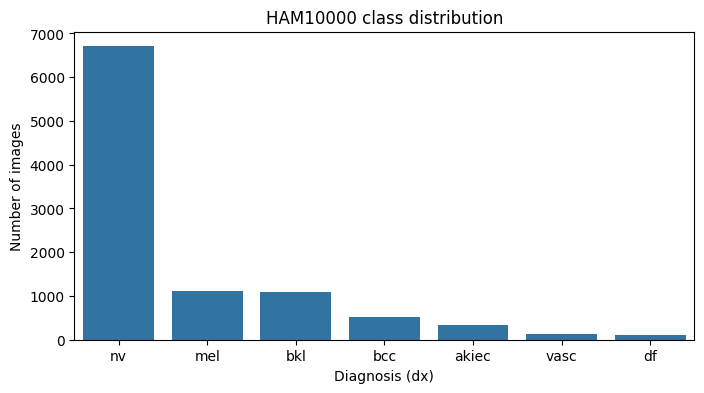

In [11]:
class_counts = metadata['dx'].value_counts()
print(class_counts)

plt.figure(figsize=(8, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.title("HAM10000 class distribution")
plt.xlabel("Diagnosis (dx)")
plt.ylabel("Number of images")
plt.show()


In [12]:
print(metadata['dx_type'].value_counts())
images_per_lesion = metadata.groupby('lesion_id').size()
print(f"Lesions with >1 image: {(images_per_lesion > 1).sum()} out of {len(images_per_lesion)} total lesions")


dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64
Lesions with >1 image: 1956 out of 7470 total lesions


## A3. Data Preparation & Splitting

**Leakage risk:** Because some lesions have multiple images, splitting by *image* could
put two photos of the same lesion into different splits, letting the model
recognize the lesion rather than genuinely generalizing. We split by **`lesion_id`**
instead all images belonging to one lesion go into exactly one split.

**Split strategy:** 70% train / 15% validation / 15% test, split at the lesion level
using `GroupShuffleSplit`, stratified informally by checking resulting class balance
below (sklearn's GroupShuffleSplit does not support combined group+stratify natively).

**Preprocessing:** resize to 224x224 (EfficientNetB0's expected input) and apply
`tensorflow.keras.applications.efficientnet.preprocess_input`, NOT a simple /255
normalization - EfficientNet expects its own specific scaling. This exact function is
imported from `model_utils.py`, the same module used by the Streamlit app, so training
and inference preprocessing cannot drift apart.

**Augmentation:** It is applied only to the training set (random flip, rotation, zoom) to
improve generalization given the dataset's modest size and class imbalance.


In [13]:
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(metadata, groups=metadata['lesion_id']))

train_df = metadata.iloc[train_idx].reset_index(drop=True)
temp_df = metadata.iloc[temp_idx].reset_index(drop=True)

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df['lesion_id']))

val_df = temp_df.iloc[val_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

print(f"Train: {len(train_df)} images, {train_df['lesion_id'].nunique()} lesions")
print(f"Val:   {len(val_df)} images, {val_df['lesion_id'].nunique()} lesions")
print(f"Test:  {len(test_df)} images, {test_df['lesion_id'].nunique()} lesions")

train_lesions = set(train_df['lesion_id'])
val_lesions = set(val_df['lesion_id'])
test_lesions = set(test_df['lesion_id'])

assert len(train_lesions & val_lesions) == 0, "LEAKAGE: lesion overlap between train and val"
assert len(train_lesions & test_lesions) == 0, "LEAKAGE: lesion overlap between train and test"
assert len(val_lesions & test_lesions) == 0, "LEAKAGE: lesion overlap between val and test"
print("No lesion_id overlap between splits confirmed.")


Train: 7002 images, 5229 lesions
Val:   1519 images, 1120 lesions
Test:  1494 images, 1121 lesions
No lesion_id overlap between splits confirmed.


In [14]:
for name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"--- {name} ---")
    print((df['dx'].value_counts(normalize=True) * 100).round(1))


--- train ---
dx
nv       67.4
mel      11.0
bkl      10.6
bcc       5.4
akiec     3.0
vasc      1.4
df        1.3
Name: proportion, dtype: float64
--- val ---
dx
nv       65.2
bkl      13.6
mel      10.3
bcc       4.3
akiec     3.8
vasc      1.6
df        1.3
Name: proportion, dtype: float64
--- test ---
dx
nv       66.7
mel      12.5
bkl      10.2
bcc       4.6
akiec     4.2
vasc      1.4
df        0.5
Name: proportion, dtype: float64


In [15]:
def make_dataset(df, img_dir, augment=False, batch_size=32, shuffle=False):
    label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
    paths = [os.path.join(img_dir, f"{img_id}.jpg") for img_id in df['image_id']]
    labels = [label_to_idx[dx] for dx in df['dx']]

    def _load(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, IMG_SIZE)
        img = preprocess_input(img) 
        return img, label

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths), seed=42)
    ds = ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)

    if augment:
        augmenter = tf.keras.Sequential([
            layers.RandomFlip("horizontal_and_vertical"),
            layers.RandomRotation(0.1),
            layers.RandomZoom(0.1),
        ])
        ds = ds.map(lambda x, y: (augmenter(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

BATCH_SIZE = 32
train_ds = make_dataset(train_df, IMG_DIR, augment=True, batch_size=BATCH_SIZE, shuffle=True)
val_ds = make_dataset(val_df, IMG_DIR, augment=False, batch_size=BATCH_SIZE)
test_ds = make_dataset(test_df, IMG_DIR, augment=False, batch_size=BATCH_SIZE)


## A4. Model Architecture & Justification

**Architecture:** EfficientNetB0 pretrained on ImageNet, used as a frozen feature
extractor with a custom classification head on top. Transfer learning is appropriate
here because HAM10000 (10k images across 7 classes) is small relative to what's needed
to train a strong CNN from scratch; ImageNet features (edges, textures, shapes)
transfer well to dermatoscopic images even though the domains differ.

**Input shape:** (224, 224, 3) - matches EfficientNetB0's expected input.
**Output shape:** (7,) - softmax probability distribution over the 7 diagnostic classes.

**Rejected alternatives:**
- *Custom CNN from scratch* - rejected due to the dataset's modest size relative to
  the number of classes and severe imbalance; would likely overfit or collapse to
  predicting the majority class (`nv`).
- *Full fine-tuning of all EfficientNet layers from the start* - rejected initially in
  favor of a two-stage approach (train head first, optionally unfreeze later) to avoid
  destroying pretrained weights early with a high learning rate.


In [16]:
def build_model(num_classes=7, input_shape=(224, 224, 3), fine_tune_base=False):
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=input_shape,
        pooling="avg",
    )
    base_model.trainable = fine_tune_base

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=fine_tune_base)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model()
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 121s 7us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,442 (16.08 MB)

 Trainable params: 164,871 (644.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## A5. Training Process

**Loss:** sparse categorical cross-entropy (labels are integer-encoded, not one-hot). <br>
**Optimizer:** Adam. <br>
**Handling class imbalance:** class weights computed from the training set are passed 
to `model.fit`, so the heavily underrepresented classes (e.g. `df`) are not drowned out
by `nv`. <br>
**Overfitting controls:** dropout in the classification head, data augmentation on the 
training set only, and early stopping monitoring validation loss. <br>

Adjust `EPOCHS` and `LEARNING_RATE` below based on what you observe in the loss curves -
document any changes you make and why.


In [17]:
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=[CLASS_NAMES.index(c) for c in train_df['dx']],
)
class_weights = dict(enumerate(class_weights_arr))
print("Class weights:", {CLASS_NAMES[i]: round(w, 2) for i, w in class_weights.items()})


Class weights: {'akiec': np.float64(4.83), 'bcc': np.float64(2.63), 'bkl': np.float64(1.35), 'df': np.float64(11.24), 'mel': np.float64(1.3), 'nv': np.float64(0.21), 'vasc': np.float64(10.42)}


In [18]:
LEARNING_RATE = 1e-3
EPOCHS = 15

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
)


Epoch 1/15


W0000 00:00:1789462768.875666  148750 cpu_allocator_impl.cc:82] Allocation of 154140672 exceeds 10% of free system memory.
W0000 00:00:1789462768.955714  148750 cpu_allocator_impl.cc:82] Allocation of 154140672 exceeds 10% of free system memory.
W0000 00:00:1789462769.035034  148750 cpu_allocator_impl.cc:82] Allocation of 156905472 exceeds 10% of free system memory.
W0000 00:00:1789462769.242129  148750 cpu_allocator_impl.cc:82] Allocation of 57802752 exceeds 10% of free system memory.
W0000 00:00:1789462769.268147  148750 cpu_allocator_impl.cc:82] Allocation of 57802752 exceeds 10% of free system memory.


219/219 ━━━━━━━━━━━━━━━━━━━━ 198s 877ms/step - accuracy: 0.3930 - loss: 1.5725 - val_accuracy: 0.5280 - val_loss: 1.2542 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 2467s 11s/step - accuracy: 0.5054 - loss: 1.2796 - val_accuracy: 0.5398 - val_loss: 1.2411 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 188s 854ms/step - accuracy: 0.5494 - loss: 1.1461 - val_accuracy: 0.5991 - val_loss: 1.0700 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 187s 852ms/step - accuracy: 0.5468 - loss: 1.1029 - val_accuracy: 0.5747 - val_loss: 1.0653 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 187s 849ms/step - accuracy: 0.5701 - loss: 1.0297 - val_accuracy: 0.6735 - val_loss: 0.8850 - learning_rate: 0.0010
Epoch 6/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 185s 842ms/step - accuracy: 0.5701 - loss: 1.0216 - val_accuracy: 0.6570 - val_loss: 0.9031 - learning_rate: 0.0010
Epoch 7/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 182s 826ms/step - accuracy: 0.5860 -

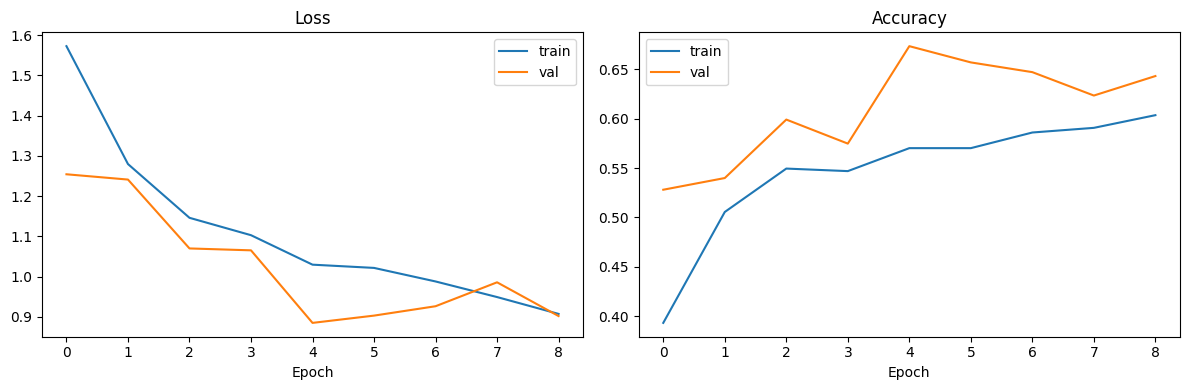

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='val')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='val')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()


## A6. Evaluation & Results

Report a confusion matrix and per-class precision/recall/F1 — not just overall accuracy,
since `nv` dominates the dataset and a model that always predicts `nv` would still score
misleadingly high on raw accuracy.


In [20]:
y_true = []
y_pred = []
y_probs = []

for images, labels in test_ds:
    probs = model.predict(images, verbose=0)
    y_probs.extend(probs)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))


              precision    recall  f1-score   support

       akiec       0.56      0.49      0.53        63
         bcc       0.49      0.53      0.51        68
         bkl       0.37      0.43      0.40       152
          df       0.17      0.71      0.27         7
         mel       0.33      0.60      0.43       187
          nv       0.94      0.74      0.83       996
        vasc       0.45      0.95      0.62        21

    accuracy                           0.67      1494
   macro avg       0.48      0.64      0.51      1494
weighted avg       0.76      0.67      0.70      1494



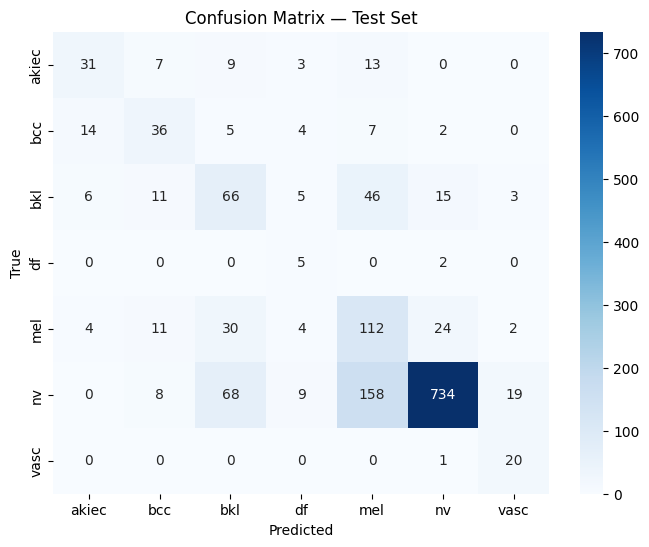

In [21]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix — Test Set')
plt.show()


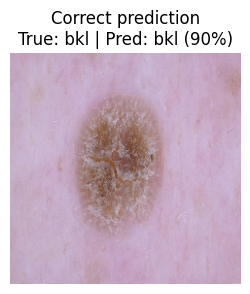

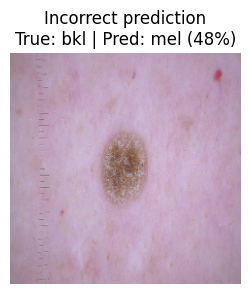

In [22]:
correct_idx = np.where(y_true == y_pred)[0]
incorrect_idx = np.where(y_true != y_pred)[0]

test_paths = [os.path.join(IMG_DIR, f"{img_id}.jpg") for img_id in test_df['image_id']]

def show_example(idx, title_prefix):
    img = load_img(test_paths[idx], target_size=IMG_SIZE)
    true_label = CLASS_NAMES[y_true[idx]]
    pred_label = CLASS_NAMES[y_pred[idx]]
    confidence = y_probs[idx][y_pred[idx]]
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.title(f"{title_prefix}\nTrue: {true_label} | Pred: {pred_label} ({confidence:.0%})")
    plt.axis('off')
    plt.show()

if len(correct_idx) > 0:
    show_example(correct_idx[0], "Correct prediction")
if len(incorrect_idx) > 0:
    show_example(incorrect_idx[0], "Incorrect prediction")


### Bonus: Grad-CAM 

Grad-CAM shows which region of the image most influenced the prediction, which is
useful for sanity-checking that the model is looking at the lesion itself and not things such as
a ruler or sticker in the corner of the photo or a known issue in some dermoscopy
datasets.


In [24]:
import cv2

def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name="top_conv"):
    grad_model = tf.keras.models.Model(
        [model.inputs], [base_model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

sample_idx = incorrect_idx[0] if len(incorrect_idx) > 0 else 0
sample_img = load_img(test_paths[sample_idx], target_size=IMG_SIZE)
sample_arr = preprocess_image(sample_img)

try:
    heatmap = make_gradcam_heatmap(sample_arr, model, base_model)
    heatmap_resized = cv2.resize(heatmap, IMG_SIZE)
    plt.figure(figsize=(4, 4))
    plt.imshow(sample_img)
    plt.imshow(heatmap_resized, cmap='jet', alpha=0.4)
    plt.title("Grad-CAM overlay")
    plt.axis('off')
    plt.show()
except Exception as e:
    print(f"Grad-CAM failed, likely due to layer name mismatch: {e}")
    print("Run base_model.summary() and update last_conv_layer_name above.")


/home/student/sep15/env/lib/python3.10/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_243']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


Grad-CAM failed, likely due to layer name mismatch: "Exception encountered when calling Functional.call().\n\n\x1b135576487218720\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[150., 129., 138.],\n         [151., 127., 140.],\n         [151., 127., 140.],\n         ...,\n         [161., 140., 159.],\n         [164., 139., 161.],\n         [164., 139., 161.]],\n\n        [[151., 128., 138.],\n         [151., 130., 139.],\n         [153., 127., 138.],\n         ...,\n         [165., 141., 163.],\n         [164., 141., 161.],\n         [164., 139., 160.]],\n\n        [[153., 130., 140.],\n         [152., 132., 141.],\n         [154., 128., 139.],\n         ...,\n         [165., 141., 163.],\n         [165., 142., 162.],\n         [164., 141., 161.]],\n\n        ...,\n\n        [[149., 127., 140.],\n         [154., 132., 145.],\n         [154., 132., 145.],\n         ...,\n         [158., 134., 150.],\n         [157., 135., 148.],\n         [156., 134., 147.]],\n\n  

## A7. Model Export

The model is saved in Keras's native `.keras` format. The preprocessing pipeline that
MUST be reapplied at inference time is defined once in `model_utils.py`
(`preprocess_image` function) and imported by both this notebook and `streamlit_app.py`
- so there is no risk of the two drifting apart.

**Exact preprocessing pipeline (for the record):**
1. Convert image to RGB
2. Resize to 224x224
3. Apply `tensorflow.keras.applications.efficientnet.preprocess_input`
   (NOT simple division by 255 - EfficientNet uses its own input scaling)
4. Add batch dimension -> shape (1, 224, 224, 3)



In [25]:
import tensorflow as tf
print("TensorFlow version used for saving:", tf.__version__)

os.makedirs("saved_model", exist_ok=True)
model.save("saved_model/ham10000_efficientnetb0.keras")
print("Model saved to saved_model/ham10000_efficientnetb0.keras")


TensorFlow version used for saving: 2.21.0
Model saved to saved_model/ham10000_efficientnetb0.keras


## A8. Limitations, Ethics & Next Steps

**Data bias / generalisation limits (fill in based on your actual data exploration):**
- HAM10000 images come from a limited set of source institutions/populations (mostly
  Austrian and Australian clinics) - performance on other skin tones, ethnicities, or
  scanners is unknown and likely worse than test-set performance suggests.
- The dataset's class imbalance (heavily skewed toward `nv`) means rarer but more
  dangerous classes (e.g. `df`) have less data to learn from.

**Ethical considerations:**
- **False negatives** (missing a melanoma, classifying it as benign) are the most
  dangerous failure mode - they could delay a patient seeking real care.
- **False positives** (flagging a benign lesion as concerning) cause unnecessary anxiety
  and downstream healthcare costs, but are lower-stakes than false negatives.
- This asymmetry means accuracy alone is an insufficient metric - recall on `mel`
  specifically deserves scrutiny (check your classification_report above).
- A model like this must never replace clinical judgement or biopsy-based confirmation;
  at best it could serve as a triage/second-opinion aid under direct clinical oversight.

**What would be needed before real-world clinical use:**
- External validation on data from different populations, scanners, and skin tones.
- Prospective clinical trial evaluating patient outcomes, not just offline accuracy.
- Regulatory approval as a medical device (e.g. FDA/CE marking) with defined intended use.
- Ongoing monitoring for model drift as patient populations and imaging equipment change.
